# ADMTSK: the Dombi T-norm and the six combinations of the article

This notebook follows, one step at a time, the classifier of

> G. Xue, L. Hu, J. Wang and S. Ablameyko, "ADMTSK: a high-dimensional
> Takagi-Sugeno-Kang fuzzy system based on adaptive Dombi T-norm", *IEEE Transactions on
> Fuzzy Systems*, vol. 33, no. 6, 2025.

on Colon, one of the datasets of the article. ADMTSK computes the firing strength of a
rule with the Dombi T-norm, whose parameter is set from the number of features, and uses
a Gaussian membership function bounded below by $1/e$. The article trains with six
combinations of learning rate and batch size and reports the best for each dataset; the
notebook runs the six. It is a short version of the script
`examples/reproductions/admtsk_2025.py`, which repeats the ten folds five times and also
runs Leukemia; here one repetition on Colon runs in a few minutes.

1. settings and reproducibility;
2. the data;
3. one fold with the defaults;
4. what the fitted model looks like;
5. the six combinations over ten folds, next to the article.

## 1. Settings and reproducibility

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import torch
from sklearn.datasets import fetch_openml
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import MinMaxScaler

import highfis
from highfis import ADMTSKClassifier

In [2]:
SEED = 0
FOLDS = 10
THREADS = 4

# The six combinations of the article: learning rate and fraction of the training samples
# in a batch.
COMBINATIONS = [(0.01, 0.1), (0.01, 0.2), (0.001, 0.1), (0.001, 0.2), (0.0001, 0.1), (0.0001, 0.2)]

# Table V of the article, Colon: mean test accuracy in percent, the best of the six.
ARTICLE = 86.33

torch.set_num_threads(THREADS)
torch.use_deterministic_algorithms(True)
highfis.set_mf_cache_enabled(False)

## 2. The data

Colon is a gene-expression dataset: 62 tissue samples, 2000 genes, two classes. OpenML
stores it as a sparse matrix.

In [3]:
bunch = fetch_openml(data_id=1432, as_frame=False, parser="liac-arff")
data = bunch.data.toarray() if hasattr(bunch.data, "toarray") else bunch.data
features = np.asarray(data, dtype=np.float32)
labels = np.unique(bunch.target, return_inverse=True)[1]

print(f"{features.shape[0]} samples, {features.shape[1]} features")
print(f"samples per class: {np.bincount(labels).tolist()}")

62 samples, 2000 features
samples per class: [40, 22]


The first of ten folds is followed in detail. The article scales the inputs to [0, 1],
with the range of the training part. A test part has six or seven samples.

In [4]:
folds = StratifiedKFold(n_splits=FOLDS, shuffle=True, random_state=SEED)
train, test = next(folds.split(features, labels))

scaler = MinMaxScaler().fit(features[train])
x_train, x_test = scaler.transform(features[train]), scaler.transform(features[test])
y_train, y_test = labels[train], labels[test]

print(f"training: {len(x_train)} samples, test: {len(x_test)} samples")

training: 55 samples, test: 7 samples


## 3. One fold with the defaults

Three rules with centres at 0, 0.5 and 1 and spreads of one, consequents starting at
zero, Adam for 50 epochs with batches of 10% of the training samples. These are the
defaults of `ADMTSKClassifier`. Above 1000 features its learning rate is 0.001, so the
defaults are the third of the six combinations.

In [5]:
model = ADMTSKClassifier(random_state=SEED).fit(x_train, y_train)

print(f"learning rate: {model.learning_rate_}, batch size: {model.batch_size_}")
print(f"training accuracy: {100 * model.score(x_train, y_train):.1f}%")
print(f"test accuracy: {100 * model.score(x_test, y_test):.1f}%")

learning rate: 0.001, batch size: 6
training accuracy: 100.0%
test accuracy: 85.7%


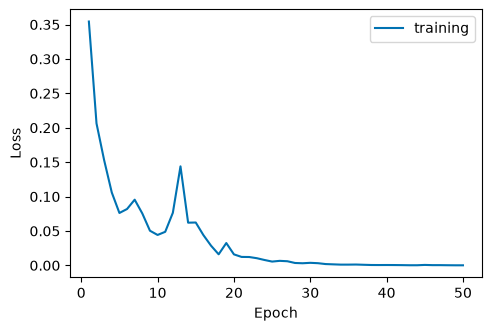

In [6]:
model.plot_history()

## 4. What the fitted model looks like

With 2000 features, a product of membership degrees would underflow. The Dombi T-norm
with the parameter of the article keeps the weights of the rules distinct:

In [7]:
report = model.firing_diagnostics(x_train)
print(f"samples with the same weight on every rule: {100 * report['uniform_fraction']:.0f}%")
print(f"mean weight of each rule: {np.round(report['mean_firing'], 3).tolist()}")
print(f"effective number of rules per sample: {report['effective_rules']:.2f} of {report['n_rules']}")

samples with the same weight on every rule: 0%
mean weight of each rule: [0.217, 0.536, 0.248]
effective number of rules per sample: 2.75 of 3


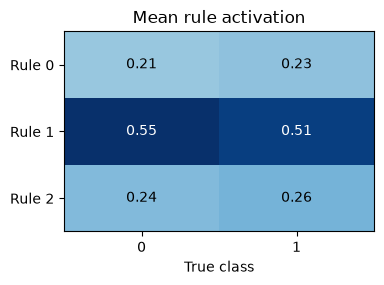

In [8]:
fig, ax = plt.subplots(figsize=(4, 2.6))
model.plot_rule_activation(x_train, y_train, ax=ax)
plt.show()

The confusion matrix and the margins on the training part:

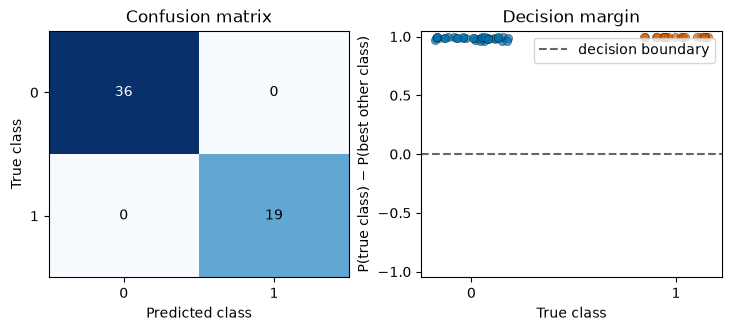

In [9]:
model.plot_diagnostics(x_train, y_train)

A summary of the model and of its training, in one call:

In [10]:
model.summary()

ADMTSKClassifier
  task               classification, 2 classes
  features           2000 seen in fit, 2000 used by the model
  rules              3 (rule base: coco)
  fuzzy sets         3 per feature, GaussianPiMF
  firing strength    RuleLayer, T-norm AdaptiveDombiTNorm
  defuzzifier        SumBasedDefuzzifier
  consequents        ClassificationConsequentLayer
  parameters         24006 trainable (12000 antecedent, 12006 consequent)
Training (batch size 6)
  phase     epochs   rate  loss first -> last  accuracy
  training      50  0.001    0.3544 -> 0.0001    1.0000

How the rules produce the prediction of the first test sample. The output is the sum of
what each rule contributes, and the predicted class is the one with the largest value:

In [11]:
model.explain(x_test[0])

Prediction: 1
Output, the sum of the contributions of the 3 rules: 0: -0.27, 1: +1.26
Rule 1, weight 0.48: contributes 0: +1.20, 1: -0.71
    IF all 2000 features are medium
Rule 2, weight 0.28: contributes 0: -0.84, 1: +1.11
    IF all 2000 features are high
Rule 0, weight 0.24: contributes 0: -0.63, 1: +0.85
    IF all 2000 features are low

How well the rules cover the samples: for each sample, the mean membership degree in its
best-matching rule. A test sample with a coverage well below the training samples would
lie outside the region the rules were built on:

In [12]:
inside, outside = model.coverage(x_train), model.coverage(x_test)
print(f"training part: min {inside.min():.2f}, median {np.median(inside):.2f}")
print(f"test part:     min {outside.min():.2f}, median {np.median(outside):.2f}")

training part: min 0.96, median 0.97
test part:     min 0.97, median 0.97


## 5. The six combinations

The article trains with three learning rates and two batch sizes, and reports, for each
dataset and each model, the best of the six mean accuracies. The loop below runs the six
over the ten folds.

In [13]:
results = {combination: [] for combination in COMBINATIONS}

for train, test in StratifiedKFold(n_splits=FOLDS, shuffle=True, random_state=SEED).split(features, labels):
    scaler = MinMaxScaler().fit(features[train])
    a_train, a_test = scaler.transform(features[train]), scaler.transform(features[test])
    for learning_rate, batch_fraction in COMBINATIONS:
        fitted = ADMTSKClassifier(
            learning_rate=learning_rate,
            batch_size=max(1, round(batch_fraction * len(train))),
            random_state=SEED,
        ).fit(a_train, labels[train])
        results[learning_rate, batch_fraction].append(100 * fitted.score(a_test, labels[test]))

print(f"{'learning rate':>13s} {'batch':>6s} {'highFIS':>8s} {'std':>6s}")
for (learning_rate, batch_fraction), scores in results.items():
    print(f"{learning_rate:13g} {batch_fraction:6.0%} {np.mean(scores):8.2f} {np.std(scores):6.2f}")

best = max(np.mean(scores) for scores in results.values())
print(f"\nbest of the six: {best:.2f}   article: {ARTICLE:.2f}")

learning rate  batch  highFIS    std
         0.01    10%    85.95  14.18
         0.01    20%    79.05   7.21
        0.001    10%    84.05  14.45
        0.001    20%    80.71   9.55
       0.0001    10%    87.38  11.72
       0.0001    20%    85.71  10.96

best of the six: 87.38   article: 86.33


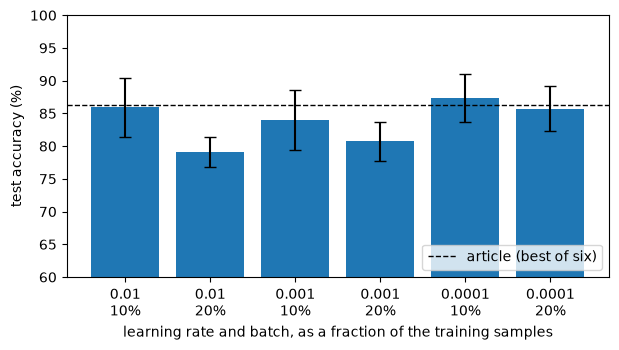

In [14]:
names = [f"{learning_rate:g}\n{batch_fraction:.0%}" for learning_rate, batch_fraction in COMBINATIONS]
means = [np.mean(results[combination]) for combination in COMBINATIONS]
errors = [np.std(results[combination]) / np.sqrt(FOLDS) for combination in COMBINATIONS]

fig, ax = plt.subplots(figsize=(7, 3.4))
ax.bar(range(len(COMBINATIONS)), means, yerr=errors, capsize=4)
ax.axhline(ARTICLE, color="black", linestyle="--", linewidth=1, label="article (best of six)")
ax.set_xticks(range(len(COMBINATIONS)), names)
ax.set_xlabel("learning rate and batch, as a fraction of the training samples")
ax.set_ylabel("test accuracy (%)")
ax.set_ylim(60, 100)
ax.legend(loc="lower right")
plt.show()

The bars are the standard error of the mean over the ten folds. The choice among the six
moves the accuracy by several points. For your own data, choose the combination on a
validation part of the training data.